DATA INGESTION

In [0]:
import pandas as pd
import numpy as np

In [0]:
order_items_refunds = spark.read.table("analystlab.default.order_item_refunds_1").toPandas()

display(order_items_refunds)

order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
1,4/6/2012 11:32,57,57,49.99
2,4/13/2012 1:09,74,74,49.99
3,4/15/2012 7:03,71,71,49.99
4,4/17/2012 20:00,118,118,49.99
5,4/22/2012 20:53,116,116,49.99
6,5/4/2012 11:59,147,147,49.99
7,5/12/2012 2:41,186,186,49.99
8,5/16/2012 13:06,191,191,49.99
9,5/24/2012 16:00,179,179,49.99
10,5/30/2012 17:20,199,199,49.99


In [0]:
# Display column names
order_items_refunds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1731 entries, 0 to 1730
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   order_item_refund_id  1731 non-null   int64  
 1   created_at            1731 non-null   object 
 2   order_item_id         1731 non-null   int64  
 3   order_id              1731 non-null   int64  
 4   refund_amount_usd     1731 non-null   float64
dtypes: float64(1), int64(3), object(1)
memory usage: 67.7+ KB


In [0]:
order_items_refunds.columns

Index(['order_item_refund_id', 'created_at', 'order_item_id', 'order_id',
       'refund_amount_usd'],
      dtype='object')

In [0]:
order_items_refunds.shape

(1731, 5)

**Identify missing values and duplicate records**

In [0]:
# Check missing values in each column
print("Missing values:")
print(order_items_refunds.isnull().sum())

Missing values:
order_item_refund_id    0
created_at              0
order_item_id           0
order_id                0
refund_amount_usd       0
dtype: int64


In [0]:
 # Check the total number of missing values
print("\nTotal missing values:")
print(order_items_refunds.isnull().sum().sum())


Total missing values:
0


In [0]:
 # Check duplicate records
print("\nDuplicate rows:")
print(order_items_refunds.duplicated().sum())


Duplicate rows:
0


In [0]:
 # Check duplicate refund IDs
print("\nDuplicate refund IDs:")
print(order_items_refunds['order_item_refund_id'].duplicated().sum())


Duplicate refund IDs:
0


Clean and prepare the data.

In [0]:
 # Convert created_at into datetime format
order_items_refunds['created_at'] = pd.to_datetime(
    order_items_refunds['created_at'],
    errors='coerce'
)

# Check the updated data types
print(order_items_refunds.dtypes)

# Display the first five records
order_items_refunds.head()

order_item_refund_id             int64
created_at              datetime64[ns]
order_item_id                    int64
order_id                         int64
refund_amount_usd              float64
dtype: object


,order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
0,1,2012-04-06 11:32:00,57,57,49.99
1,2,2012-04-13 01:09:00,74,74,49.99
2,3,2012-04-15 07:03:00,71,71,49.99
3,4,2012-04-17 20:00:00,118,118,49.99
4,5,2012-04-22 20:53:00,116,116,49.99


In [0]:
 # Count invalid dates created during conversion
print("Invalid dates:", order_items_refunds['created_at'].isna().sum())

Invalid dates: 0


In [0]:
 # Summary of refund amounts
print(order_items_refunds['refund_amount_usd'].describe())

# Check for zero or negative refund amounts
print(
    "Zero or negative refunds:",
    (order_items_refunds['refund_amount_usd'] <= 0).sum()
)

count    1731.000000
mean       49.300225
std         4.956015
min        29.990000
25%        49.990000
50%        49.990000
75%        49.990000
max        59.990000
Name: refund_amount_usd, dtype: float64
Zero or negative refunds: 0


In [0]:
 # Check the cleaned dataset
print("Dataset shape:", order_items_refunds.shape)

print("\nMissing values:")
print(order_items_refunds.isnull().sum())

print("\nDuplicate rows:")
print(order_items_refunds.duplicated().sum())

Dataset shape: (1731, 5)

Missing values:
order_item_refund_id    0
created_at              0
order_item_id           0
order_id                0
refund_amount_usd       0
dtype: int64

Duplicate rows:
0


In [0]:
 # Summary statistics for refund amounts
order_items_refunds['refund_amount_usd'].describe()

count    1731.000000
mean       49.300225
std         4.956015
min        29.990000
25%        49.990000
50%        49.990000
75%        49.990000
max        59.990000
Name: refund_amount_usd, dtype: float64

In [0]:
 # Calculate total refunds
total_refunds = order_items_refunds['refund_amount_usd'].sum()

# Calculate average refund
average_refund = order_items_refunds['refund_amount_usd'].mean()

# Calculate median refund
median_refund = order_items_refunds['refund_amount_usd'].median()

print("Total Refunds: $", round(total_refunds, 2))
print("Average Refund: $", round(average_refund, 2))
print("Median Refund: $", round(median_refund, 2))

Total Refunds: $ 85338.69
Average Refund: $ 49.3
Median Refund: $ 49.99


In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

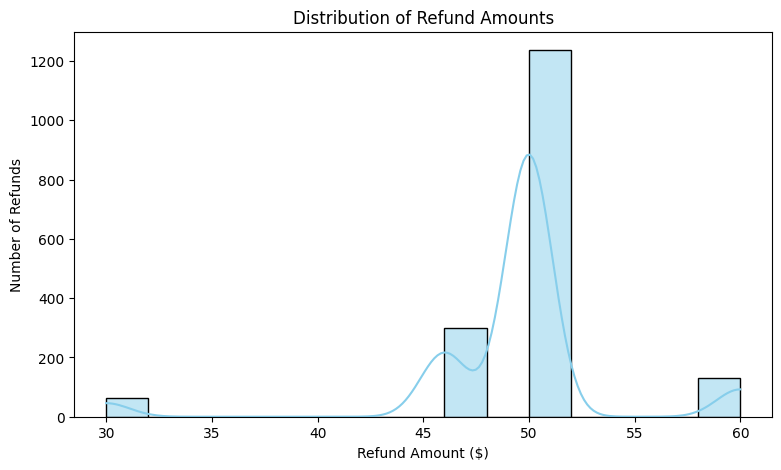

In [0]:
plt.figure(figsize=(9,5))

sns.histplot(
    order_items_refunds['refund_amount_usd'],
    bins=15,
    kde=True,
    color='skyblue'
)

plt.title('Distribution of Refund Amounts')
plt.xlabel('Refund Amount ($)')
plt.ylabel('Number of Refunds')

plt.show()

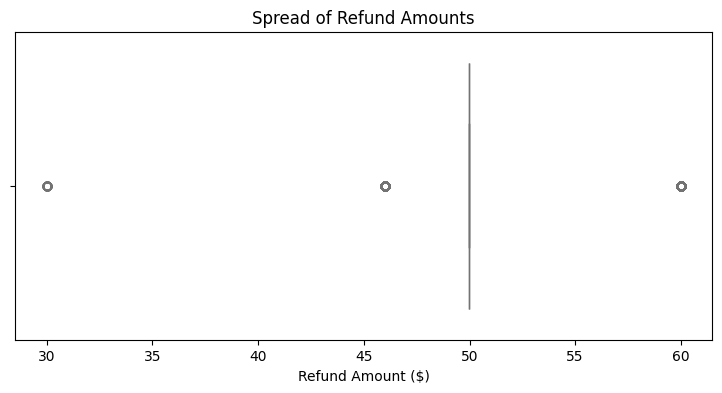

In [0]:
plt.figure(figsize=(9,4))

sns.boxplot(
    x=order_items_refunds['refund_amount_usd'],
    color='lightgreen'
)

plt.title('Spread of Refund Amounts')
plt.xlabel('Refund Amount ($)')

plt.show()

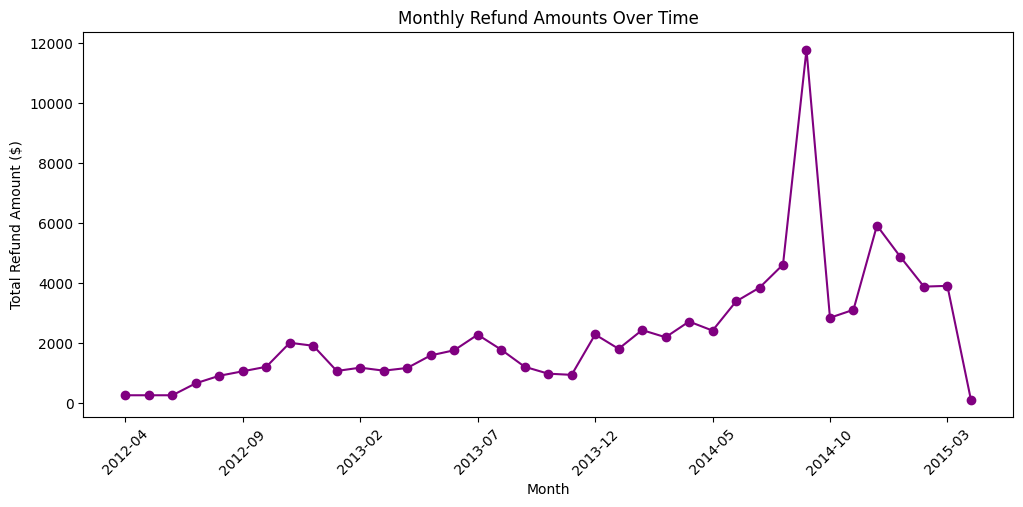

In [0]:
order_items_refunds['created_at'] = pd.to_datetime(
    order_items_refunds['created_at']
)

monthly_refunds = order_items_refunds.groupby(
    order_items_refunds['created_at'].dt.to_period('M')
)['refund_amount_usd'].sum()

plt.figure(figsize=(12,5))

monthly_refunds.index = monthly_refunds.index.astype(str)

monthly_refunds.plot(
    kind='line',
    marker='o',
    color='purple'
)

plt.title('Monthly Refund Amounts Over Time')
plt.xlabel('Month')
plt.ylabel('Total Refund Amount ($)')
plt.xticks(rotation=45)

plt.show()

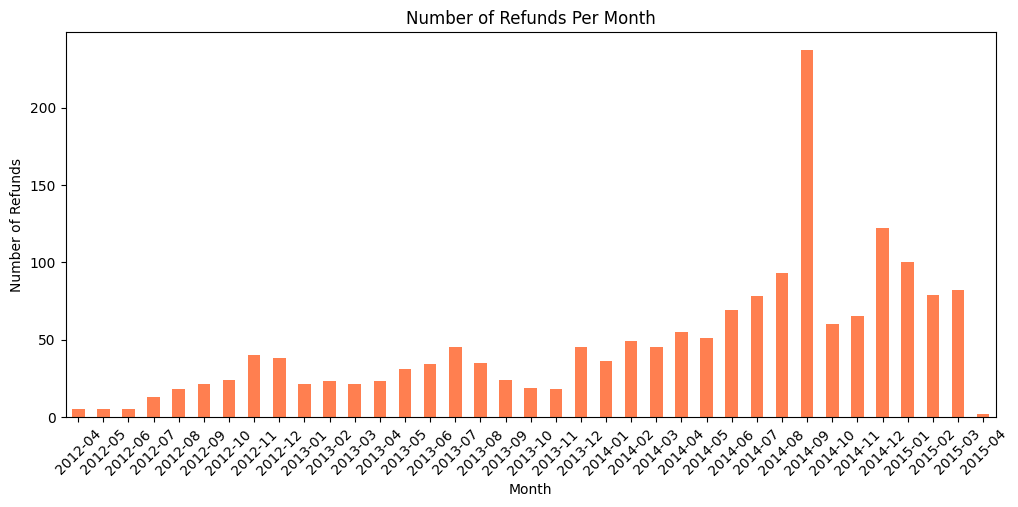

In [0]:
monthly_count = order_items_refunds.groupby(
    order_items_refunds['created_at'].dt.to_period('M')
)['order_item_refund_id'].count()

plt.figure(figsize=(12,5))

monthly_count.index = monthly_count.index.astype(str)

monthly_count.plot(
    kind='bar',
    color='coral'
)

plt.title('Number of Refunds Per Month')
plt.xlabel('Month')
plt.ylabel('Number of Refunds')
plt.xticks(rotation=45)

plt.show()

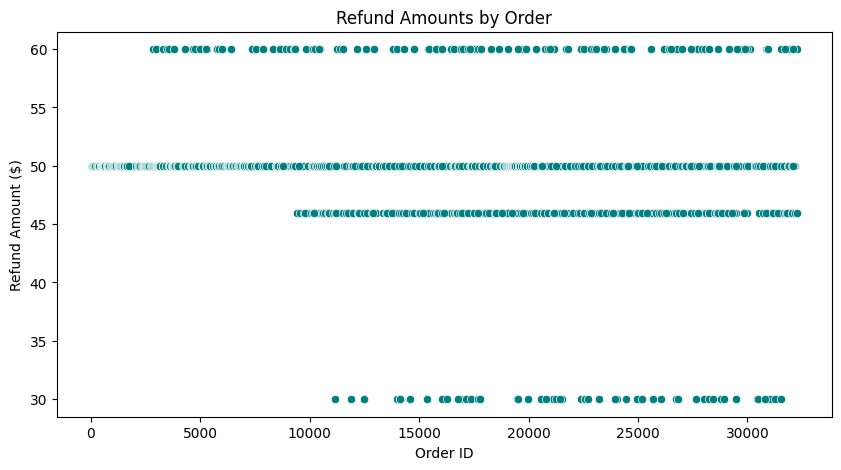

In [0]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=order_items_refunds,
    x='order_id',
    y='refund_amount_usd',
    color='teal'
)

plt.title('Refund Amounts by Order')
plt.xlabel('Order ID')
plt.ylabel('Refund Amount ($)')

plt.show()

In [0]:
  # Calculate total refunds for each order item
item_refunds = order_items_refunds.groupby('order_item_id').agg(
    total_refunds=('refund_amount_usd', 'sum'),
    refund_count=('order_item_refund_id', 'count')
).sort_values(by='total_refunds', ascending=False)

item_refunds.head(10)

,total_refunds,refund_count
order_item_id,,
39950,59.99,1
29838,59.99,1
21592,59.99,1
31853,59.99,1
12844,59.99,1
22118,59.99,1
31037,59.99,1
2846,59.99,1
2998,59.99,1


In [0]:
 # Group refunds by month
monthly_analysis = order_items_refunds.groupby(
    order_items_refunds['created_at'].dt.to_period('M')
).agg(
    total_refunds=('refund_amount_usd', 'sum'),
    number_of_refunds=('order_item_refund_id', 'count')
)

monthly_analysis

,total_refunds,number_of_refunds
created_at,,
2012-04,249.95,5
2012-05,249.95,5
2012-06,249.95,5
2012-07,649.87,13
2012-08,899.82,18
2012-09,1049.79,21
2012-10,1199.76,24
2012-11,1999.60,40
2012-12,1899.62,38


In [0]:
order_refunds = order_items_refunds.groupby('order_id').agg(
    total_refunded=('refund_amount_usd', 'sum'),
    number_of_refunds=('order_item_refund_id', 'count')
).sort_values(by='total_refunded', ascending=False)

order_refunds.head(10)

,total_refunded,number_of_refunds
order_id,,
9324,109.98,2
19518,109.98,2
19848,95.98,2
31486,95.98,2
23321,95.98,2
27061,95.98,2
28802,79.98,2
24472,79.98,2
32255,59.99,1


In [0]:
 # Filter refunds from September 2014
september_refunds = order_items_refunds[
    (order_items_refunds['created_at'].dt.year == 2014) &
    (order_items_refunds['created_at'].dt.month == 9)
]

# Display summary statistics
print("September 2014 refund records:",
      len(september_refunds))

print("Total September refunds: $",
      september_refunds['refund_amount_usd'].sum())

print("Average refund: $",
      september_refunds['refund_amount_usd'].mean())

print("Unique orders:",
      september_refunds['order_id'].nunique())

September 2014 refund records: 237
Total September refunds: $ 11773.63
Average refund: $ 49.67776371308017
Unique orders: 235


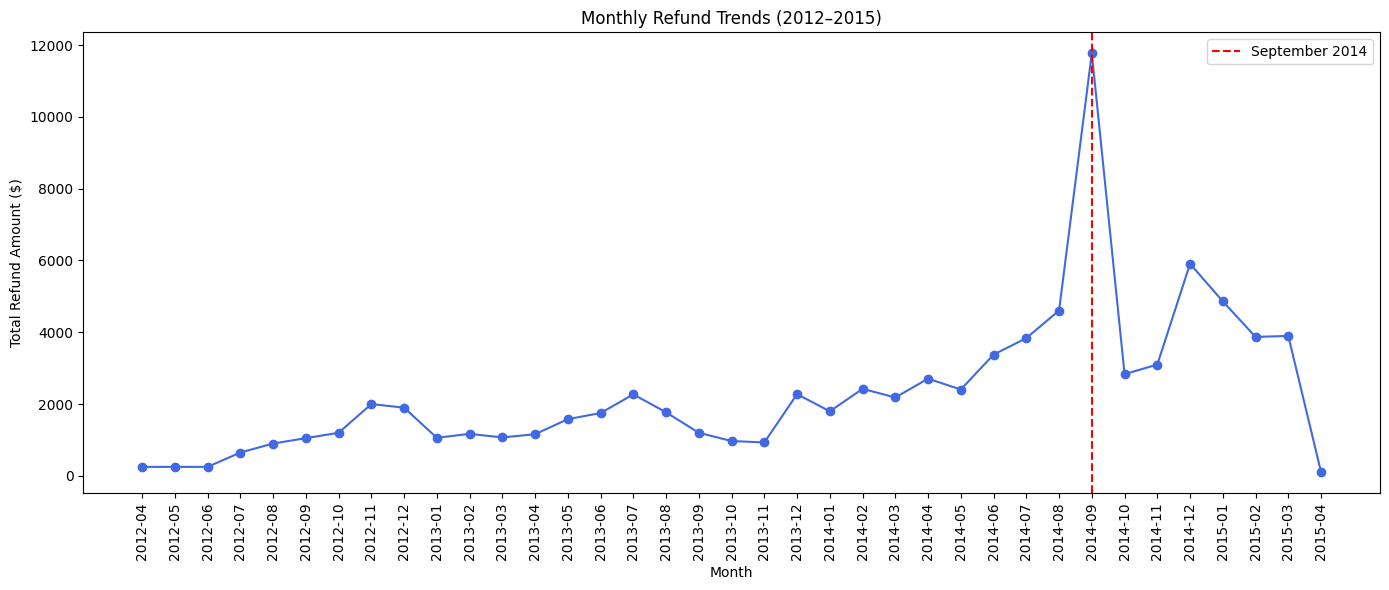

In [0]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis['total_refunds'],
    marker='o',
    color='royalblue'
)

plt.title('Monthly Refund Trends (2012–2015)')
plt.xlabel('Month')
plt.ylabel('Total Refund Amount ($)')

plt.xticks(rotation=90)

# Highlight September 2014
plt.axvline(
    x=list(monthly_analysis.index.astype(str)).index('2014-09'),
    color='red',
    linestyle='--',
    label='September 2014'
)

plt.legend()
plt.tight_layout()
plt.show()

Task 3: Statistical analysis and visualisation
-  Calculate relevant descriptive statistics.
-  Examine relationships between website traffic and orders.
-  Compare sales performance across different periods.
- Investigate the relationship between product sales and refunds.
- Create at least six meaningful visualisations

In [0]:
 # Calculate additional descriptive statistics

print("Variance:",
      order_items_refunds['refund_amount_usd'].var())

print("Standard deviation:",
      order_items_refunds['refund_amount_usd'].std())

print("Total unique orders:",
      order_items_refunds['order_id'].nunique())

print("Total unique order items:",
      order_items_refunds['order_item_id'].nunique())

Variance: 24.562086134180188
Standard deviation: 4.956015146685913
Total unique orders: 1723
Total unique order items: 1731


Examine relationships between refunds and orders

In [0]:
 # Group refunds by order
order_analysis = order_items_refunds.groupby('order_id').agg(
    number_of_refunds=('order_item_refund_id', 'count'),
    total_refund_amount=('refund_amount_usd', 'sum')
).reset_index()

# Calculate correlation
correlation = order_analysis[
    ['number_of_refunds', 'total_refund_amount']
].corr()

print(correlation)

                     number_of_refunds  total_refund_amount
number_of_refunds             1.000000             0.534768
total_refund_amount           0.534768             1.000000


Compare refund performance across different periods

In [0]:
 # Extract year from refund date
order_items_refunds['year'] = order_items_refunds['created_at'].dt.year

# Calculate yearly refund statistics
yearly_refunds = order_items_refunds.groupby('year').agg(
    total_refunds=('refund_amount_usd', 'sum'),
    number_of_refunds=('order_item_refund_id', 'count'),
    average_refund=('refund_amount_usd', 'mean')
)

print(yearly_refunds.round(2))

      total_refunds  number_of_refunds  average_refund
year                                                  
2012        8448.31                169           49.99
2013       17202.61                339           50.75
2014       46952.40                960           48.91
2015       12735.37                263           48.42


**Create at least six meaningful visualisations.**

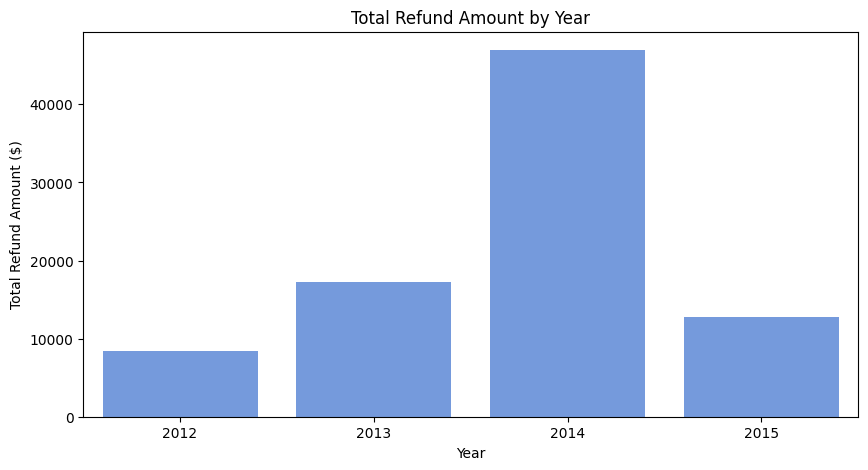

In [0]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=yearly_refunds.index,
    y=yearly_refunds['total_refunds'],
    color='cornflowerblue'
)

plt.title('Total Refund Amount by Year')
plt.xlabel('Year')
plt.ylabel('Total Refund Amount ($)')

plt.show()

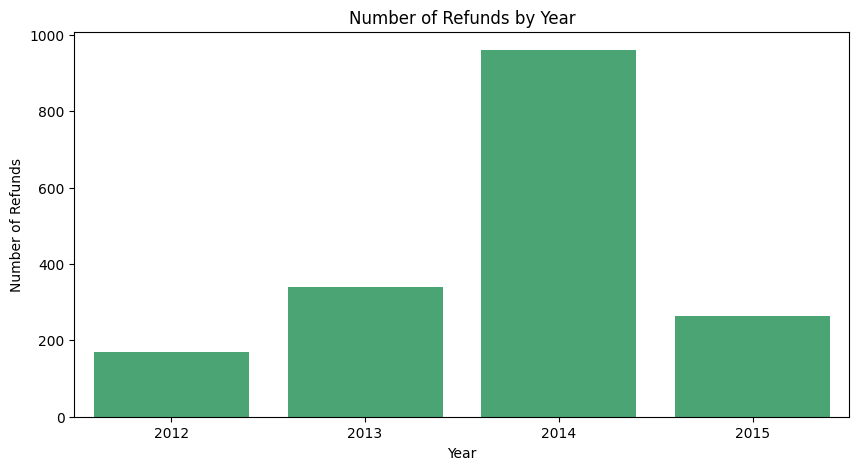

In [0]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=yearly_refunds.index,
    y=yearly_refunds['number_of_refunds'],
    color='mediumseagreen'
)

plt.title('Number of Refunds by Year')
plt.xlabel('Year')
plt.ylabel('Number of Refunds')

plt.show()

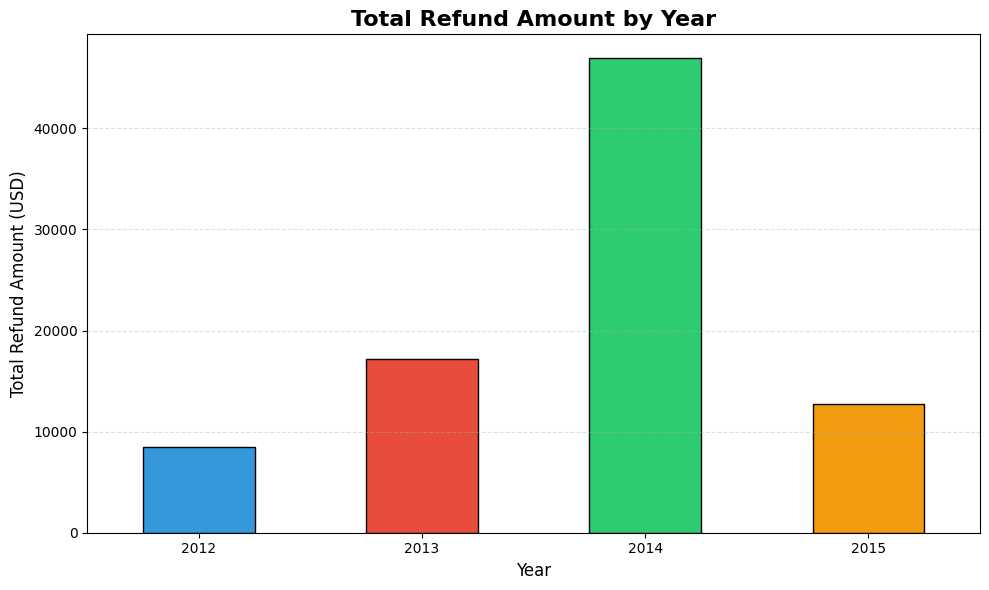

In [0]:
 
import matplotlib.pyplot as plt

# Calculate total refunds per year
annual_refunds = order_items_refunds.groupby(
    order_items_refunds['created_at'].dt.year
)['refund_amount_usd'].sum()

# Create colours for each year
colors = ['#3498DB', '#E74C3C', '#2ECC71', '#F39C12']

# Create the bar chart
plt.figure(figsize=(10, 6))

annual_refunds.plot(
    kind='bar',
    color=colors[:len(annual_refunds)],
    edgecolor='black'
)

plt.title('Total Refund Amount by Year',
          fontsize=16, fontweight='bold')

plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Refund Amount (USD)', fontsize=12)

plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


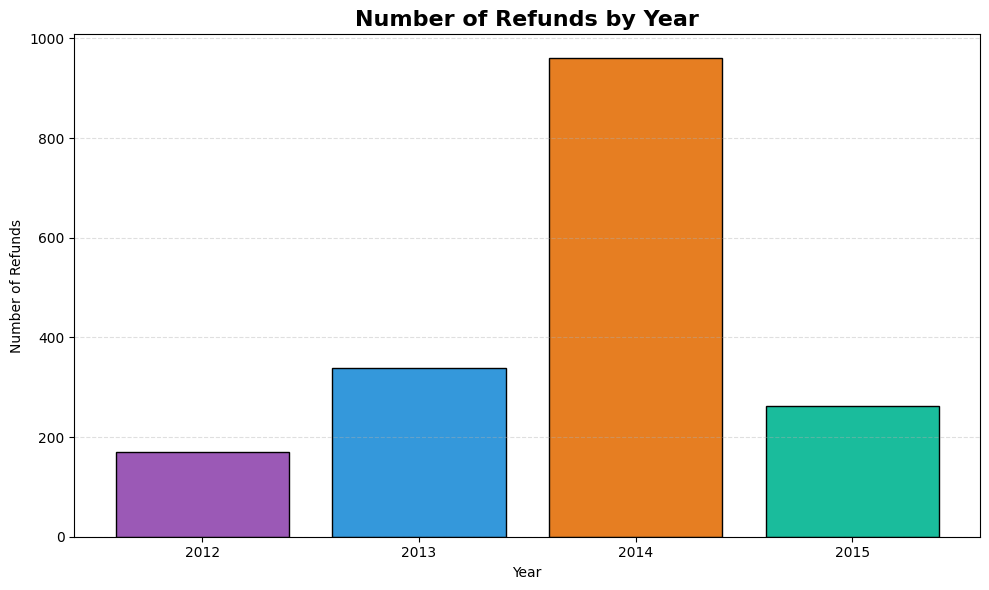

In [0]:
 
import matplotlib.pyplot as plt

# Count refunds per year
refund_counts = order_items_refunds.groupby(
    order_items_refunds['created_at'].dt.year
)['order_item_refund_id'].count()

# Create colourful bar chart
colors = ['#9B59B6', '#3498DB', '#E67E22', '#1ABC9C']

plt.figure(figsize=(10, 6))

plt.bar(
    refund_counts.index.astype(str),
    refund_counts.values,
    color=colors[:len(refund_counts)],
    edgecolor='black'
)

plt.title('Number of Refunds by Year',
          fontsize=16, fontweight='bold')

plt.xlabel('Year')
plt.ylabel('Number of Refunds')

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


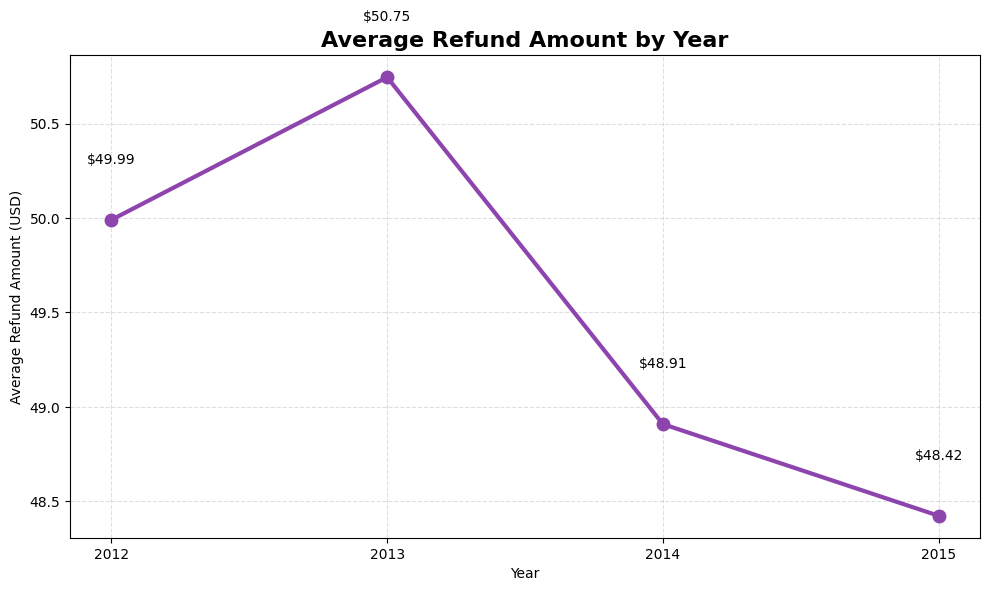

In [0]:
 
import matplotlib.pyplot as plt

# Calculate average refund amount per year
average_refunds = order_items_refunds.groupby(
    order_items_refunds['created_at'].dt.year
)['refund_amount_usd'].mean()

# Create colourful line chart
plt.figure(figsize=(10, 6))

plt.plot(
    average_refunds.index,
    average_refunds.values,
    marker='o',
    markersize=9,
    linewidth=3,
    color='#8E44AD'
)

# Add labels to each point
for year, amount in zip(average_refunds.index, average_refunds.values):
    plt.text(year, amount + 0.3, f'${amount:.2f}',
             ha='center', fontsize=10)

plt.title('Average Refund Amount by Year',
          fontsize=16, fontweight='bold')

plt.xlabel('Year')
plt.ylabel('Average Refund Amount (USD)')

plt.xticks(average_refunds.index)
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


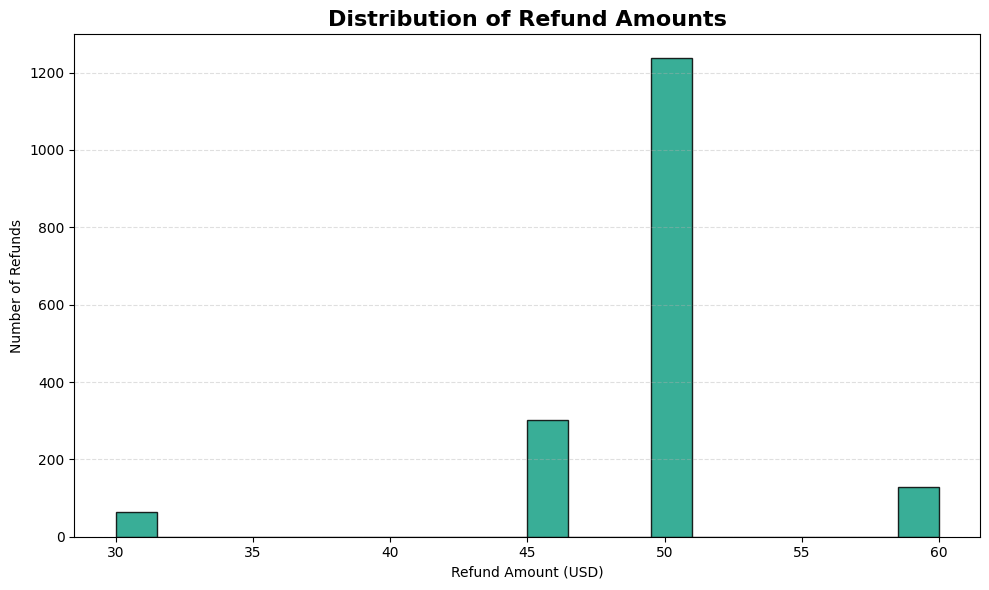

In [0]:
 
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    order_items_refunds['refund_amount_usd'],
    bins=20,
    color='#16A085',
    edgecolor='black',
    alpha=0.85
)

plt.title('Distribution of Refund Amounts',
          fontsize=16, fontweight='bold')

plt.xlabel('Refund Amount (USD)')
plt.ylabel('Number of Refunds')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


Task 4: Interpretation and Recommendations
- 4.1 Introduction
The analysis of the e-commerce refund dataset was conducted to understand refund patterns, identify changes in refund activity over time and determine how refunds may affect business performance.

The analysis focused on the number of refunds, total refund amounts, average refund values and the distribution of individual refunds. These measures provide insight into customer purchasing behaviour and possible areas where the business can improve its sales processes, customer experience and marketing performance.
4.2 Interpretation of findings
1. Refund activity over time
The analysis identified a noticeable increase in refund activity between 2012 and 2014, followed by a significant decrease in 2015.

The yearly refund figures were:
Year	Number of refunds	Total refunds (USD)
2012	169	$8,448.31
2013	339	$17,202.61
2014	960	$46,952.40
2015	263	$12,735.37

Interpretation:

2014 recorded the highest refund activity, with 960 refunds totalling $46,952.40. This represents a substantial increase compared with previous years.

In 2015, refund activity decreased to 263 refunds. This could indicate improved customer satisfaction, fewer purchases, changes in sales volume or differences in business operations. Further investigation would be required to establish the reason.
2. Average refund amount
The average refund amounts varied slightly across the four years.
- 2012: $49.99
- 2013: $50.75
- 2014: $48.91
- 2015: $48.42
Interpretation:

The average refund amount remained relatively stable, ranging from approximately $48 to $51.

This suggests that although the number of refunds changed considerably, the average value of individual refunds did not experience major fluctuations.

The business should therefore investigate the reasons behind the high refund volume rather than focusing only on the monetary value of individual refunds.
3. Distribution of refund amounts
The refund distribution showed that most refund transactions were concentrated around $49.99.

The descriptive statistics also indicated:
Measurement	Refund amount
Average	$49.30
Median	$49.99
Minimum	$29.99
Maximum	$59.99
Standard deviation	$4.96

Interpretation:

The similarity between the average and median suggests that refund amounts are concentrated around a relatively consistent value.

This may indicate that refunds are commonly associated with products or transactions within a similar price range.

The business should investigate whether particular products or product categories account for a large proportion of refunds.
4. Relationship between refund numbers and refund values
The analysis indicates that years with higher refund volumes also recorded higher total refund amounts.

For example, 2014 had both the highest number of refunds and the highest total refund value.

Interpretation:

This suggests that refund frequency is an important contributor to the overall financial impact of refunds.

Reducing unnecessary refunds could help the business retain more revenue and improve operational efficiency.

4.3 Business recommendations
Based on the findings, the following recommendations are proposed.
A. Improving sales performance
1. Improve product descriptions: Provide accurate product descriptions, specifications and images to ensure customers understand what they are purchasing.

2. Monitor frequently refunded products: Identify products responsible for the highest refund volumes and investigate whether product quality, pricing or customer expectations contribute to refunds.

3. Improve product quality control: Introduce quality checks before products are dispatched to customers.

4. Monitor refund trends: Track refund numbers and values monthly to identify unusual increases and take corrective action early.
B. Improving customer engagement
1. Collect customer feedback: Ask customers to provide reasons when requesting refunds. This will help the business understand customer dissatisfaction.

2. Improve customer support: Provide accessible assistance before and after purchases to help customers resolve product-related issues.

3. Improve the purchasing experience: Ensure product information, pricing and delivery expectations are clearly communicated.

4. Introduce customer retention strategies: Consider loyalty programmes, personalised offers and follow-up communication to encourage repeat purchases.
C. Improving marketing performance
1. Promote products with lower refund rates: Identify products that generate good sales and relatively few refunds, and consider prioritising them in marketing campaigns.

2. Improve advertising accuracy: Ensure advertisements accurately represent products to avoid creating unrealistic customer expectations.

3. Monitor campaign performance: Evaluate marketing campaigns based on sales generated, customer engagement and subsequent refunds rather than clicks alone.

4. Use customer purchasing insights: Use purchasing and refund information to develop more relevant promotions and targeted marketing campaigns.

4.4 Key findings
The analysis produced the following important findings:
Finding	Business implication
2014 recorded the highest refund activity.	Investigate the reasons behind the increase.
2015 recorded significantly fewer refunds.	Examine what changed and whether the improvement can be maintained.
Average refund values remained relatively stable.	Focus on refund frequency and product-related issues.
Most refunds were concentrated around $49.99.	Investigate products within this price range.
Refund volume influences total refund expenditure.	Reducing unnecessary refunds can protect revenue.

4.5 Conclusion
The refund analysis provided useful insights into customer purchasing behaviour and the financial impact of refunds on the business.

The findings showed that refund activity increased significantly between 2012 and 2014 before declining in 2015. Although the number of refunds changed considerably, the average refund amount remained relatively stable at approximately $49.

The business should focus on understanding why customers request refunds, improving product quality, providing accurate product information and strengthening customer support.

Furthermore, marketing activities should focus on promoting products that generate sustainable sales and positive customer experiences.

- Overall, combining sales performance, customer feedback and refund information can help the business make better decisions, improve customer satisfaction, reduce unnecessary refunds and support long-term revenue growth.